# Aula 1 — Trabalho prático

**Ensinando o oscilador amortecido para um modelo**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

MATRICULA = 202312345        # <- troque pelo número de matrícula (só dígitos)

# Parâmetros do oscilador

A = 1 # amplitude inicial da oscilação, em metros
gama = 0.5 # taxa de amortecimento
omega = 2 * np.pi   # frequência angular da oscilação, em rad/s.
sigma = 0.1 # desvio padrão do erro de medição de oscilação
t_max = 3.0  # Tempo máximo da simulação, em segundos.

def lei_verdadeira(t):
    return A * np.exp(-gama * t) * np.cos(omega * t)

def gerar_dados(N, semente):
    """Simula N medidas da posição, feitas a intervalos regulares entre 0 e t_max."""
    rng = np.random.default_rng(semente)
    t = np.linspace(0, t_max, N)
    x = lei_verdadeira(t) + rng.normal(0, sigma, N)
    return t, x

## Parte 1 — Os dados

formato de T: (100, 1)   formato de x: (100,)


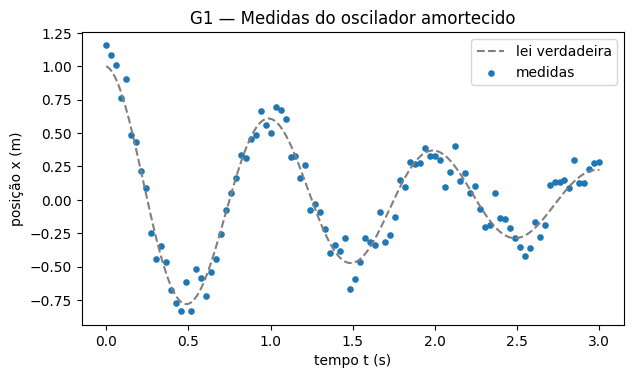

In [2]:
t, x = gerar_dados(100, MATRICULA)
T = t.reshape(-1, 1)            # (100, 1): 100 amostras, 1 atributo
print("formato de T:", T.shape, "  formato de x:", x.shape)

tt = np.linspace(0, t_max, 500)  # malha fina, só para desenhar a curva
plt.figure(figsize=(7, 3.8))
plt.plot(tt, lei_verdadeira(tt), "--", color="gray", label="lei verdadeira")
plt.scatter(t, x, s=14, label="medidas")
plt.xlabel("tempo t (s)")
plt.ylabel("posição x (m)")
plt.title("G1 — Medidas do oscilador amortecido")
plt.legend()
plt.show()

## Parte 2 — Qual grau de polinômio é melhor para prever a posição do oscilador ?

grau | EQM treino | EQM teste   (m²)
   1 |     0.1935 |    0.1499
   2 |     0.1831 |    0.1506
   3 |     0.1730 |    0.1563
   4 |     0.1290 |    0.1398
   5 |     0.1093 |    0.1220
   6 |     0.0872 |    0.0846
   7 |     0.0860 |    0.0830
   8 |     0.0209 |    0.0270
   9 |     0.0190 |    0.0269
  10 |     0.0089 |    0.0142
  11 |     0.0088 |    0.0138
  12 |     0.0085 |    0.0137
  13 |     0.0082 |    0.0127


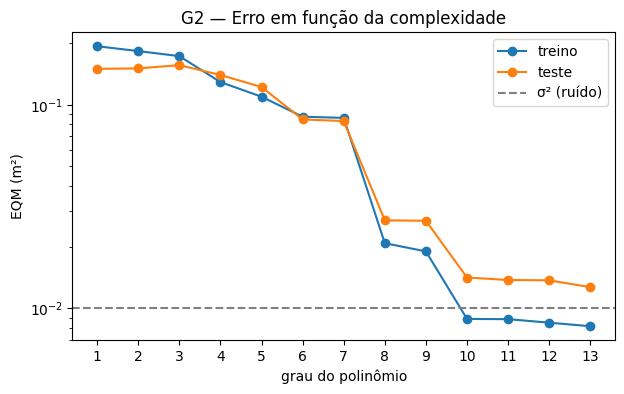

In [3]:
T_tr, T_te, x_tr, x_te = train_test_split(T, x, test_size=0.3, random_state=9)

graus = range(1, 14)
eqm_treino, eqm_teste = [], []
for g in graus:
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(g), LinearRegression())
    modelo.fit(T_tr, x_tr)
    eqm_treino.append(mean_squared_error(x_tr, modelo.predict(T_tr)))
    eqm_teste.append(mean_squared_error(x_te, modelo.predict(T_te)))

print("grau | EQM treino | EQM teste   (m²)")
for g, a, b in zip(graus, eqm_treino, eqm_teste):
    print(f"{g:4d} | {a:10.4f} | {b:9.4f}")

plt.figure(figsize=(7, 4))
plt.semilogy(graus, eqm_treino, "o-", label="treino")
plt.semilogy(graus, eqm_teste, "o-", label="teste")
plt.axhline(sigma**2, ls="--", color="gray", label="σ² (ruído)")
plt.xlabel("grau do polinômio")
plt.ylabel("EQM (m²)")
plt.title("G2 — Erro em função da complexidade")
plt.xticks(list(graus))
plt.legend()
plt.show()

## Parte 3 — Escolha do grau por validação cruzada

grau | EQM validação cruzada (m²)
   1 | 0.2036
   2 | 0.1961
   3 | 0.1964
   4 | 0.1385
   5 | 0.1191
   6 | 0.1071
   7 | 0.1125
   8 | 0.0336
   9 | 0.0345
  10 | 0.0123   <- menor
  11 | 0.0124
  12 | 0.0132
  13 | 0.0183


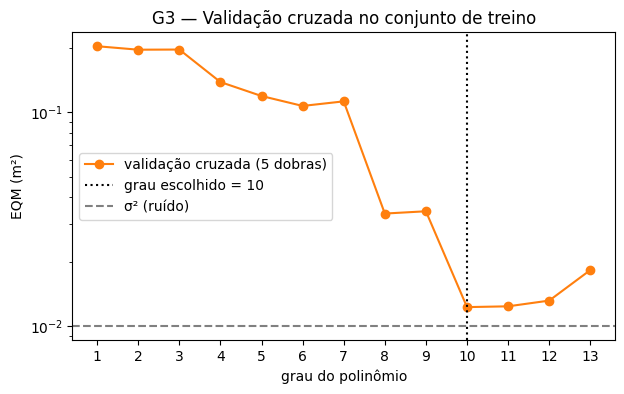

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=0)
eqm_cv = []
for g in graus:
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(g), LinearRegression())
    notas = cross_val_score(modelo, T_tr, x_tr, cv=kf, scoring="neg_mean_squared_error")
    eqm_cv.append(-notas.mean())               # troca de sinal: EQM positivo

grau_cv = list(graus)[np.argmin(eqm_cv)]
print("grau | EQM validação cruzada (m²)")
for g, e in zip(graus, eqm_cv):
    print(f"{g:4d} | {e:.4f}" + ("   <- menor" if g == grau_cv else ""))

plt.figure(figsize=(7, 4))
plt.semilogy(graus, eqm_cv, "o-", color="tab:orange", label="validação cruzada (5 dobras)")
plt.axvline(grau_cv, ls=":", color="black", label=f"grau escolhido = {grau_cv}")
plt.axhline(sigma**2, ls="--", color="gray", label="σ² (ruído)")
plt.xlabel("grau do polinômio"); plt.ylabel("EQM (m²)")
plt.title("G3 — Validação cruzada no conjunto de treino")
plt.xticks(list(graus)); plt.legend(); plt.show()

grau escolhido: 10
REQM no teste: 0.119 m   (sigma = 0.1 m)
R² no teste:   0.906


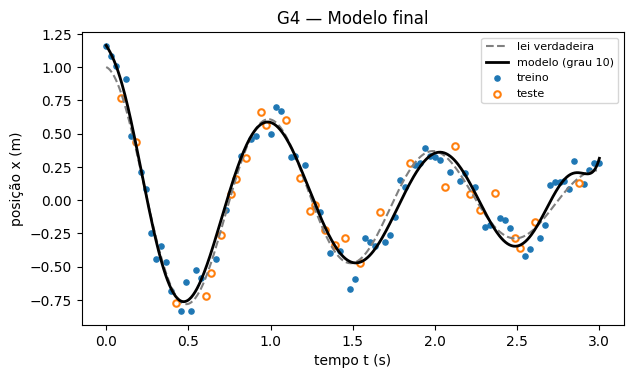

In [5]:
modelo_final = make_pipeline(StandardScaler(), PolynomialFeatures(grau_cv), LinearRegression())
modelo_final.fit(T_tr, x_tr)
x_prev = modelo_final.predict(T_te)            # avaliação única no teste
reqm = np.sqrt(mean_squared_error(x_te, x_prev))
r2 = r2_score(x_te, x_prev)
print(f"grau escolhido: {grau_cv}")
print(f"REQM no teste: {reqm:.3f} m   (sigma = {sigma} m)")
print(f"R² no teste:   {r2:.3f}")

plt.figure(figsize=(7, 3.8))
plt.plot(tt, lei_verdadeira(tt), "--", color="gray", label="lei verdadeira")
plt.plot(tt, modelo_final.predict(tt.reshape(-1, 1)), color="black", lw=2, label=f"modelo (grau {grau_cv})")
plt.scatter(T_tr, x_tr, s=14, label="treino")
plt.scatter(T_te, x_te, s=22, facecolor="white", edgecolor="tab:orange", linewidth=1.5, label="teste")
plt.xlabel("tempo t (s)"); plt.ylabel("posição x (m)")
plt.title("G4 — Modelo final")
plt.legend(fontsize=8); plt.show()

## Parte 4 — Quantidade de dados e desempenho

   N | grau | REQM teste (m)
  20 |    4 | 0.691
  40 |   10 | 0.123
 100 |   10 | 0.119
 200 |   11 | 0.101
 500 |   12 | 0.098


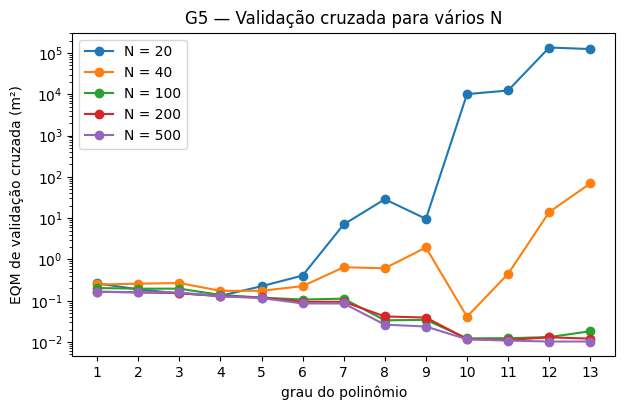

In [6]:
def escolher_grau(N, semente):
    t, x = gerar_dados(N, semente)
    T_tr, T_te, x_tr, x_te = train_test_split(t.reshape(-1, 1), x,
                                              test_size=0.3, random_state=9)
    curva = []
    for g in graus:
        m = make_pipeline(StandardScaler(), PolynomialFeatures(g), LinearRegression())
        notas = cross_val_score(m, T_tr, x_tr, cv=kf, scoring="neg_mean_squared_error")
        curva.append(-notas.mean())
    g_melhor = list(graus)[np.argmin(curva)]
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(g_melhor), LinearRegression())
    modelo.fit(T_tr, x_tr)
    reqm = np.sqrt(mean_squared_error(x_te, modelo.predict(T_te)))
    return g_melhor, reqm, modelo, curva

resultados, curvas = {}, {}
plt.figure(figsize=(7, 4.2))
print("   N | grau | REQM teste (m)")
for N in [20, 40, 100, 200, 500]:
    g_melhor, reqm_N, modelo, curva = escolher_grau(N, MATRICULA)
    resultados[N] = (g_melhor, reqm_N)
    curvas[N] = curva
    plt.semilogy(graus, curva, "o-", label=f"N = {N}")
    print(f"{N:4d} | {g_melhor:4d} | {reqm_N:.3f}")
plt.xlabel("grau do polinômio"); plt.ylabel("EQM de validação cruzada (m²)")
plt.title("G5 — Validação cruzada para vários N")
plt.xticks(list(graus)); plt.legend(); plt.show()